# 06. Влияют ли гиперпараметры LightGBM на выводы?

Во всех экспериментах (E0, E1, E2) у LightGBM одни и те же **фиксированные** параметры (`src/models.py`), подбиралось только число деревьев (ранняя остановка по val_a)

Здесь проверяем: **меняются ли выводы, если параметры подобрать?**

**Правила (как во всём проекте):**
- train — веса модели (деревья);
- **val_a — выбор** параметров (та же роль, что у числа деревьев, отбора признаков E1 и выбора h в E2);
- **val_b — проверка** выбора: на ней ничего не выбирается;
- **test не трогаем**: он использован один раз в `05_final_comparison`, финальная таблица остаётся как есть.

**Сокращённый вариант из-за железа**: одно обучение на полном train занимает 20–100 с, памяти ~7.6 ГБ, запуски только по очереди. Поэтому вместо сетки или Optuna — 3 осмысленных варианта параметров + LambdaRank для каждого из 5 наборов признаков (25 обучений с базовой конфигурацией, ~30 мин). Проба на E0  уже показала, что параметры двигают GAUC меньше, чем смена seed, так что широкий поиск не окупается.

Результаты сохраняются в `artifacts/HP/`; прежние результаты (`artifacts/E*/`) не меняются.

In [1]:
import sys, time, resource, pickle, json, gc
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

import numpy as np
import polars as pl
import lightgbm as lgb
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score
from IPython.display import display, Markdown

pl.Config.set_tbl_rows(40)
pl.Config.set_tbl_cols(20)
pl.Config.set_fmt_str_lengths(60)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

def peak_ram_gb():
    """Пиковая память процесса (ядра ноутбука) с момента старта, ГБ."""
    return resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024**2

from src.candidates import load_candidates
from src.selection import catalog, load_matrix
from src.decay import load_decay
from src.metrics import evaluate, ranking_metrics
from src.models import LGB_PARAMS, MAX_ROUNDS, EARLY_STOP, train_lgb
from src import memguard

ART = ROOT / "artifacts" / "HP"
ART.mkdir(parents=True, exist_ok=True)
res0, res1, res2 = (pickle.load(open(ROOT / "artifacts" / e / "results.pkl", "rb")) for e in ["E0", "E1", "E2"])

## 1. Наборы признаков и данные

Пять наборов — ровно те, что в финальном сравнении, с тем же порядком колонок:


- E0 - `artifacts/E0/results.pkl` 
- E1 - 10 признаков жадного отбора 
- E0 + E1 - объединение из `03_E1`
- E2 - 48 затухающих счётчиков, выбранная конфигурация h 
- E0 + E2 - E0, затем E2 

Все признаки (36 + 10 + 48 = 94 колонки) читаем **один раз** на каждую часть и храним как numpy float32. В float64 они заняли бы ~3 ГБ, в float32 — ~1.5 ГБ. Из-за float32 базовая модель может чуть отличаться от сохранённой, поэтому базовую конфигурацию **обучаем заново здесь же**: все сравнения идут внутри одного пайплайна.

In [ ]:
SETS = {
    "E0": res0["features"],
    "E1": res1["features"],
    "E0 + E1": res1["union_features"],
    "E2": res2["features"],
    "E0 + E2": [*res0["features"], *res2["features"]],
}
ALL = list(dict.fromkeys(f for cols in SETS.values() for f in cols))
E1_ONLY = [f for f in res1["features"] if f not in res0["features"]]
print({k: len(v) for k, v in SETS.items()}, "всего колонок:", len(ALL))

memguard.check(4.0, "загрузка признаков")
cands = load_candidates()
cat = catalog()
feats0 = pl.read_parquet(ROOT / "data" / "processed" / "features_E0.parquet")

t0 = time.perf_counter()
M, y, META = {}, {}, {}
for part in ["train", "val_a", "val_b"]:
    d = cands.filter(pl.col("part") == part)
    m = (load_matrix(d, E1_ONLY, cat)
         .join(load_decay(d, res2["config"]), on="row_id", how="left", maintain_order="left")
         .join(feats0, on="row_id", how="left", maintain_order="left"))
    # метки сопоставляются по позиции — порядок строк обязан совпадать 
    assert m["row_id"].equals(d["row_id"])
    
    M[part] = m.select(ALL).cast(pl.Float32).to_numpy()
    y[part] = d["label"].to_numpy()
    META[part] = d.select("row_id", "uid", "day", "label")
    del m, d
    gc.collect()

del cands, feats0

gc.collect()

COL = {f: i for i, f in enumerate(ALL)}
print(f"загрузка {time.perf_counter() - t0:.0f} с; матрицы {sum(a.nbytes for a in M.values()) / 1024**3:.2f} ГБ; "
      f"пиковая память {peak_ram_gb():.1f} ГБ")

{'E0': 36, 'E1': 10, 'E0 + E1': 46, 'E2': 48, 'E0 + E2': 84} всего колонок: 94


загрузка 9 с; матрицы 1.44 ГБ; пиковая память 3.7 ГБ


## 2. Какие варианты пробуем и почему

Базовые параметры: `num_leaves` 127, `min_data_in_leaf` 500, lr 0.05, `feature_fraction` и `bagging_fraction` 0.8, L2 = 1.

| вариант | что меняем | что проверяет |
|---|---|---|
| `base` | ничего | точка отсчёта (повтор финальной модели) |
| `simpler` | `num_leaves` 31 | не слишком ли сложные деревья (E1 с 10 признаками почти не переобучается: train 0.463 / val_a 0.468) |
| `complex` | `num_leaves` 255, `min_data_in_leaf` 200 | не мало ли мощности наборам с 46–84 признаками |
| `regularized` | `min_data_in_leaf` 2000, `lambda_l2` 10 | поможет ли сильная регуляризация против дрейфа train → val |
| `lambdarank` | целевая функция LambdaRank по группам «пользователь × день», ранняя остановка по NDCG@10 | гипотеза H7: оптимизация ранжирования напрямую вместо logloss |

У LambdaRank скор — не вероятность, поэтому LogLoss и ROC-AUC для него не считаем, только групповые метрики.

**Правило выбора (до запуска):** для каждого набора берём вариант с лучшим GAUC на val_a, но заменяем им `base`, только если выигрыш **больше 0.002** (2σ шума одиночного прогона). Затем смотрим, подтверждается ли выигрыш на val_b.

Прогоны сохраняются в `artifacts/HP/runs.json` после каждого обучения: если WSL упадёт, при перезапуске готовые пропускаются.

In [3]:
VARIANTS = {
    "base": {},
    "simpler": {"num_leaves": 31},
    "complex": {"num_leaves": 255, "min_data_in_leaf": 200},
    "regularized": {"min_data_in_leaf": 2000, "lambda_l2": 10.0},
    "lambdarank": {"objective": "lambdarank", "metric": "ndcg", "eval_at": [10]},
}
THRESHOLD = 0.002


def group_sizes(meta):
    """Размеры групп «пользователь × день» в порядке строк (строки группы идут подряд)"""
    runs = meta.select((pl.struct("uid", "day") != pl.struct("uid", "day").shift()).fill_null(True).cum_sum().alias("g"))
    sizes = runs.group_by("g", maintain_order=True).len()["len"].to_numpy()
    assert len(sizes) == meta.select("uid", "day").unique().height, "группы идут не подряд"
    return sizes


GROUPS = {p: group_sizes(META[p]) for p in ["train", "val_a"]}


def train_rank(X_tr, y_tr, X_va, y_va, params):
    """LambdaRank: те же параметры деревьев, ранняя остановка по NDCG@10 на val_a"""
    params = {**LGB_PARAMS, **params}
    dtr = lgb.Dataset(X_tr, y_tr, group=GROUPS["train"], free_raw_data=True)
    dva = lgb.Dataset(X_va, y_va, group=GROUPS["val_a"], reference=dtr)
    t0 = time.perf_counter()
    model = lgb.train(params, dtr, num_boost_round=MAX_ROUNDS, valid_sets=[dva], valid_names=["val_a"],
                      callbacks=[lgb.early_stopping(EARLY_STOP, verbose=False)])
    return model, time.perf_counter() - t0


def score_part(model, X, part, is_rank):
    """Метрики на части; у LambdaRank нет вероятностей — LogLoss не считаем"""
    df = META[part].with_columns(p=pl.Series(model.predict(X)))
    if is_rank:
        r = {"logloss": float("nan"), "roc_auc": float(roc_auc_score(df["label"], df["p"])), **ranking_metrics(df, "p")}
    else:
        r = evaluate(df, "p")
    return r, df.select("row_id", "p")

In [ ]:
RUNS_PATH = ART / "runs.json"
runs = json.loads(RUNS_PATH.read_text()) if RUNS_PATH.exists() else {}
t_all = time.perf_counter()

for set_name, cols in SETS.items():
    idx = [COL[f] for f in cols]

    for var, params in VARIANTS.items():
        key = f"{set_name}|{var}"
        if key in runs:
            continue

        memguard.check(2.0, key)
        X_tr = M["train"][:, idx]
        X_va = M["val_a"][:, idx]

        is_rank = var == "lambdarank"
        if is_rank:
            model, sec = train_rank(X_tr, y["train"], X_va, y["val_a"], params)
        else:
            model, _, sec = train_lgb(X_tr, y["train"], X_va, y["val_a"], params)
        del X_tr

        row = {"set": set_name, "variant": var, "trees": model.best_iteration, "seconds": round(sec, 1)}
        for part, X in [("val_a", X_va), ("val_b", M["val_b"][:, idx])]:
            r, pred = score_part(model, X, part, is_rank)
            row[part] = {k: float(r[k]) for k in ["logloss", "roc_auc", "gauc", "ndcg@10", "recall@10"]}
            # базовые прогнозы нужны ноутбуку 07 как seed 42
            if var == "base":
                pred.write_parquet(ART / f"pred_base_{set_name}_{part}.parquet")

        runs[key] = row

        RUNS_PATH.write_text(json.dumps(runs, ensure_ascii=False, indent=1))

        print(f"{key:24s} деревьев {row['trees']:4d}  {sec:5.0f} с  GAUC val_a {row['val_a']['gauc']:.4f}  "
              f"val_b {row['val_b']['gauc']:.4f}  память {peak_ram_gb():.1f} ГБ", flush=True)
        del model, X_va
        gc.collect()
        
print(f"всего {time.perf_counter() - t_all:.0f} с")

всего 0 с


## 3. Проверка воспроизводимости

`base` — та же конфигурация, что в финальном сравнении. Если пайплайн тот же, метрики должны совпасть с сохранёнными в `artifacts/E*/results.pkl` (с точностью до эффекта float32).

In [5]:
saved = {
    "E0": (res0["metrics"], "LightGBM"), "E1": (res1["metrics"], "E1 LightGBM"), "E0 + E1": (res1["metrics"], "E0 + E1 LightGBM"),
    "E2": (res2["metrics"], "E2 LightGBM"), "E0 + E2": (res2["metrics"], "E0 + E2 LightGBM"),
}
check = []
for s, (mt, name) in saved.items():
    for part in ["val_a", "val_b"]:
        old = mt.filter((pl.col("модель") == name) & (pl.col("часть") == part))["gauc"].item()
        new = runs[f"{s}|base"][part]["gauc"]
        check.append({"набор": s, "часть": part, "GAUC сохранённый": round(old, 5), "GAUC повтор": round(new, 5), "разница": round(new - old, 5)})
pl.DataFrame(check)

набор,часть,GAUC сохранённый,GAUC повтор,разница
str,str,f64,f64,f64
"""E0""","""val_a""",0.57403,0.57403,0.0
"""E0""","""val_b""",0.56903,0.56903,0.0
"""E1""","""val_a""",0.5725,0.5725,0.0
"""E1""","""val_b""",0.56919,0.56919,0.0
"""E0 + E1""","""val_a""",0.57651,0.57651,0.0
"""E0 + E1""","""val_b""",0.57331,0.57331,0.0
"""E2""","""val_a""",0.57595,0.57595,0.0
"""E2""","""val_b""",0.57264,0.57264,0.0
"""E0 + E2""","""val_a""",0.57687,0.57687,0.0


## 4. Результаты: насколько каждый вариант отличается от `base`

Δ GAUC = вариант − `base` того же набора. Серая полоса — ±0.002, шум одиночного прогона : всё, что внутри, нельзя отличить от случайности.

In [ ]:
tab = pl.DataFrame([
    {"набор": r["set"], "вариант": r["variant"], "деревьев": r["trees"], "сек": r["seconds"],
     **{f"{m} {p}": r[p][m] for p in ["val_a", "val_b"] for m in ["gauc", "ndcg@10", "logloss"]}}
    for r in runs.values()
])

base = tab.filter(pl.col("вариант") == "base").select("набор", pl.col("gauc val_a").alias("_ba"), pl.col("gauc val_b").alias("_bb"))
tab = (tab.join(base, on="набор", how="left", maintain_order="left")
       .with_columns((pl.col("gauc val_a") - pl.col("_ba")).alias("Δ GAUC val_a"), (pl.col("gauc val_b") - pl.col("_bb")).alias("Δ GAUC val_b"))
       .drop("_ba", "_bb"))


display(tab.select("набор", "вариант", "деревьев", "сек", "gauc val_a", "Δ GAUC val_a", "gauc val_b", "Δ GAUC val_b",
                   "ndcg@10 val_b", "logloss val_b").with_columns(pl.col(pl.Float64).round(4)))

набор,вариант,деревьев,сек,gauc val_a,Δ GAUC val_a,gauc val_b,Δ GAUC val_b,ndcg@10 val_b,logloss val_b
str,str,i64,f64,f64,f64,f64,f64,f64,f64
"""E0""","""base""",253,40.0,0.574,0.0,0.569,0.0,0.7651,0.4558
"""E0""","""simpler""",520,54.2,0.5737,-0.0003,0.5701,0.0011,0.7647,0.4557
"""E0""","""complex""",253,51.4,0.5744,0.0004,0.5701,0.001,0.7658,0.4565
"""E0""","""regularized""",228,47.1,0.5733,-0.0007,0.5706,0.0015,0.7654,0.4555
"""E0""","""lambdarank""",303,68.8,0.5762,0.0022,0.5733,0.0042,0.7704,NaN
"""E1""","""base""",123,22.7,0.5725,0.0,0.5692,0.0,0.7645,0.4633
"""E1""","""simpler""",230,22.5,0.5719,-0.0006,0.5692,0.0001,0.7642,0.463
"""E1""","""complex""",101,20.0,0.5724,-0.0001,0.5685,-0.0007,0.7646,0.4636
"""E1""","""regularized""",126,21.5,0.5725,0.0,0.5689,-0.0002,0.7647,0.4632


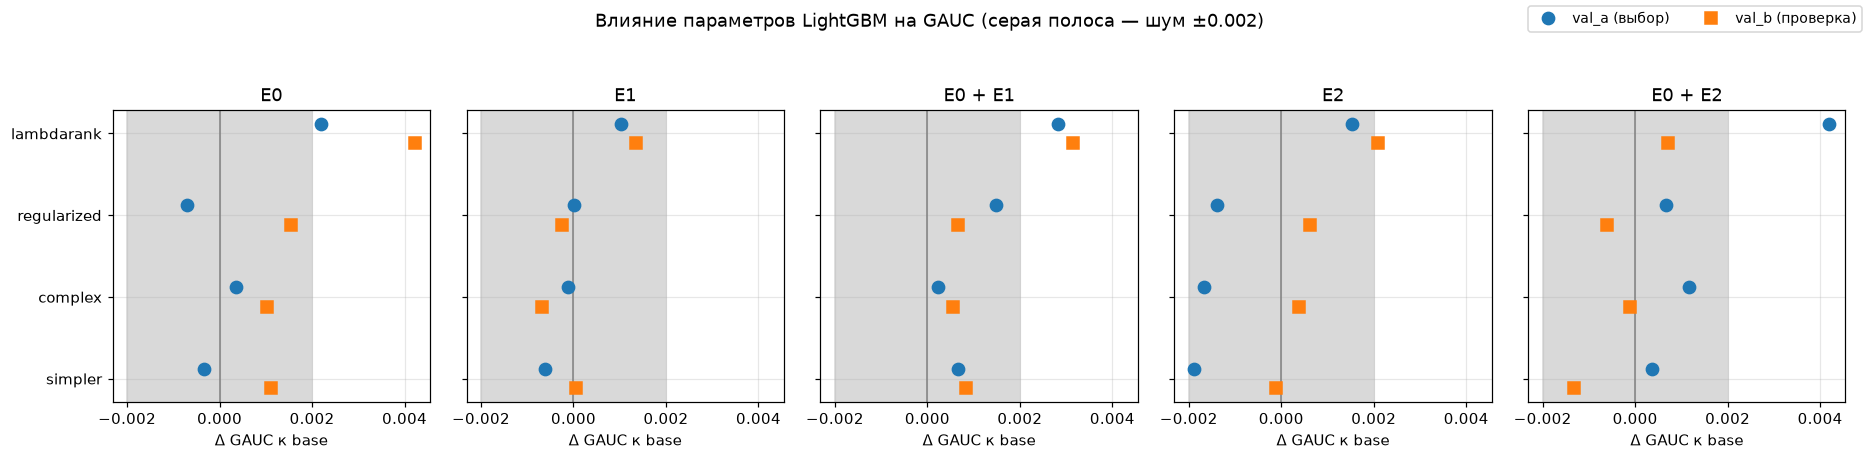

In [ ]:
set_names = list(SETS)
var_names = [v for v in VARIANTS if v != "base"]

fig, axes = plt.subplots(1, len(set_names), figsize=(17, 4.2), sharex=True, sharey=True)
for ax, s in zip(axes, set_names):
    d = tab.filter(pl.col("набор") == s)
    ax.axvspan(-THRESHOLD, THRESHOLD, color="0.85", zorder=0)
    ax.axvline(0, color="0.5", lw=1)

    for j, v in enumerate(var_names):
        r = d.filter(pl.col("вариант") == v)
        ax.plot(r["Δ GAUC val_a"], [j + 0.12], "o", color="C0", ms=8, label="val_a (выбор)" if j == 0 else None)
        ax.plot(r["Δ GAUC val_b"], [j - 0.12], "s", color="C1", ms=8, label="val_b (проверка)" if j == 0 else None)
    
    ax.set_yticks(range(len(var_names)), var_names)
    ax.set_title(s)
    ax.set_xlabel("Δ GAUC к base")


fig.legend(*axes[0].get_legend_handles_labels(), loc="upper right", ncol=2, fontsize=9)
fig.suptitle("Влияние параметров LightGBM на GAUC (серая полоса — шум ±0.002)")
plt.tight_layout(rect=(0, 0, 1, 0.93))
plt.show()

## 5. Выбор по правилу и проверка на val_b

Применяем правило, зафиксированное в разделе 2: лучший по GAUC val_a, если он лучше `base` больше чем на 0.002, иначе остаётся `base`.

In [8]:
choice = []
for s in set_names:
    d = tab.filter(pl.col("набор") == s).sort("gauc val_a", descending=True)
    best = d.row(0, named=True)
    chosen = best if best["вариант"] != "base" and best["Δ GAUC val_a"] > THRESHOLD else d.filter(pl.col("вариант") == "base").row(0, named=True)
    choice.append({"набор": s, "лучший на val_a": best["вариант"], "его Δ val_a": round(best["Δ GAUC val_a"], 4),
                   "выбрано": chosen["вариант"], "Δ val_b выбранного": round(chosen["Δ GAUC val_b"], 4)})
choice = pl.DataFrame(choice)
choice

набор,лучший на val_a,его Δ val_a,выбрано,Δ val_b выбранного
str,str,f64,str,f64
"""E0""","""lambdarank""",0.0022,"""lambdarank""",0.0042
"""E1""","""lambdarank""",0.001,"""base""",0.0
"""E0 + E1""","""lambdarank""",0.0028,"""lambdarank""",0.0031
"""E2""","""lambdarank""",0.0015,"""base""",0.0
"""E0 + E2""","""lambdarank""",0.0042,"""lambdarank""",0.0007


In [9]:
# Сравнение наборов между собой: сохраняется ли порядок при любых параметрах?
pivot = (tab.select("набор", "вариант", "gauc val_b")
         .pivot(on="набор", index="вариант", values="gauc val_b")
         .with_columns([(pl.col(s) - pl.col("E0")).alias(f"{s} − E0") for s in set_names if s != "E0"]))
display(pivot.select("вариант", *[f"{s} − E0" for s in set_names if s != "E0"]).with_columns(pl.col(pl.Float64).round(4)))

вариант,E1 − E0,E0 + E1 − E0,E2 − E0,E0 + E2 − E0
str,f64,f64,f64,f64
"""base""",0.0002,0.0043,0.0036,0.0072
"""simpler""",-0.0009,0.004,0.0024,0.0048
"""complex""",-0.0015,0.0038,0.003,0.0061
"""regularized""",-0.0016,0.0034,0.0027,0.0051
"""lambdarank""",-0.0027,0.0032,0.0015,0.0037


## 6. Выводы

1. **Пайплайн воспроизводится точно.** Повтор `base` совпал с сохранёнными моделями до 5-го знака на всех наборах и обеих неделях (раздел 3). Значит, все Δ здесь — эффект параметров, а не загрузки данных
2. **Параметры деревьев почти ничего не меняют.** Ни `simpler` (31 лист), ни `complex` (255 листьев), ни `regularized` не дают выигрыша больше порога 0.002 на val_a ни для одного набора; на val_b сдвиги — того же размера, что разброс от seed. Фиксированные параметры не были узким местом, и ограничение «параметры не подбирались» снимается: подбор не меняет картину
3. **LambdaRank — единственное, что даёт устойчивый прирост .** Он лучший на val_a у всех 5 наборов и выше `base` на val_b тоже у всех 5. По правилу (выигрыш на val_a > 0.002) он выбран для E0, E0 + E1 и E0 + E2. Для одного набора выигрыш сравним с шумом seed, но знак совпал в 10 случаях из 10 (5 наборов × 2 недели)
4. **Сравнение наборов от параметров почти не зависит** (таблица разностей на val_b):
   - E0 + E1 и E0 + E2 лучше E0 при **любых** параметрах 
   - E2 − E0 положительна при всех вариантах, но сокращается  при LambdaRank;
   - E1 − E0 положительна только при `base` , при остальных вариантах отрицательна  — E1 скорее чуть хуже E0, что совпадает с test
5. **LambdaRank помогает ручным признакам больше, чем автоматическим** 
6. **Стоимость:** 25 обучений на полном train — 26 мин, пик памяти 4.0 ГБ. Полный подбор (сетка или Optuna, десятки конфигураций × 5 наборов) занял бы часы и, судя по пунктам 2–3, картину бы не изменил.


In [10]:
results = {
    "variants": VARIANTS, "threshold": THRESHOLD, "runs": runs, "table": tab, "choice": choice,
    "reproducibility": pl.DataFrame(check), "set_differences_val_b": pivot,
    "cost": {"total_train_s": float(tab["сек"].sum()), "peak_ram_gb": peak_ram_gb()},
}
with open(ART / "results.pkl", "wb") as f:
    pickle.dump(results, f)
display(results["cost"])

{'total_train_s': 1567.6999999999996, 'peak_ram_gb': 3.6610031127929688}